# Task 2 · Customer Segmentation Analysis

This notebook segments the customers of a UK online gift retailer. The file is the UCI Online Retail dataset: 541,909 invoice lines from 1 December 2010 to 9 December 2011. Many of the buyers are wholesalers.

The segments are built from recency, frequency, and monetary value, so a marketer can treat each group differently.


## 1. Setup


In [1]:
from pathlib import Path

%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 2)
pd.set_option("display.max_rows", 20)

DATA_PATH = Path("data") / "online_retail.csv"


## 2. Load, inspect, and clean


In [2]:
retail = pd.read_csv(
    DATA_PATH,
    dtype={"InvoiceNo": "string", "StockCode": "string", "Description": "string", "Country": "string"},
)
retail["InvoiceDate"] = pd.to_datetime(retail["InvoiceDate"])

print("shape", retail.shape)
print("dates", retail["InvoiceDate"].min(), "to", retail["InvoiceDate"].max())
print("duplicate rows", int(retail.duplicated().sum()))
retail.isna().sum().to_frame("nulls")


shape (541909, 8)
dates 2010-12-01 08:26:00 to 2011-12-09 12:50:00


duplicate rows 5268


,nulls
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [3]:
print("negative quantity", int((retail["Quantity"] < 0).sum()))
print("negative unit price", int((retail["UnitPrice"] < 0).sum()))
print("cancellations", int(retail["InvoiceNo"].str.startswith("C").fillna(False).sum()))
print("countries", retail["Country"].nunique())


negative quantity 10624
negative unit price 2
cancellations 9288
countries 38


Customer id is missing on 135,080 lines. Those are guest checkouts and cannot be tied to a person, so they are removed. Exact duplicate lines are removed as well.

An invoice number that starts with C is a cancellation. Quantity and unit price also go negative on returns and adjustments. Those rows are not purchases, so they are removed before the recency, frequency, and monetary figures are calculated. Descriptions are stripped so the same product is not split by a leading space. Customer id is stored as a string because it is an identifier, not a measure.


In [4]:
work = retail.drop_duplicates().copy()
work = work.dropna(subset=["CustomerID"])
work = work.loc[~work["InvoiceNo"].str.startswith("C").fillna(False)]
work = work.loc[(work["Quantity"] > 0) & (work["UnitPrice"] > 0)].copy()
work["Description"] = work["Description"].str.strip()
work["CustomerID"] = work["CustomerID"].astype(int).astype("string")
work["Revenue"] = work["Quantity"] * work["UnitPrice"]

print("purchase lines", len(work))
print("customers", work["CustomerID"].nunique())
print("remaining nulls", int(work.isna().sum().sum()))


purchase lines 392692
customers 4338
remaining nulls 0


## 3. Purchase value, frequency, and lifetime value

Average purchase value is the mean invoice total. Purchase frequency is the mean number of invoices per customer. Customer lifetime value here is the total spent during this one-year window. It is observed spend, not a forecast of future years.


In [5]:
snapshot = work["InvoiceDate"].max() + pd.Timedelta(days=1)
invoices = work.groupby(["CustomerID", "InvoiceNo"], as_index=False)["Revenue"].sum()
rfm = work.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates: (snapshot - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
)

print("customers", len(rfm))
print("average purchase value", round(invoices["Revenue"].mean(), 2))
print("median purchase value", round(invoices["Revenue"].median(), 2))
print("average purchase frequency", round(rfm["Frequency"].mean(), 2))
print("average lifetime value", round(rfm["Monetary"].mean(), 2))
print("median lifetime value", round(rfm["Monetary"].median(), 2))
rfm.describe()


customers 4338
average purchase value 479.56
median purchase value 302.58
average purchase frequency 4.27
average lifetime value 2048.69
median lifetime value 668.57


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


The average invoice is 479.56 pounds and the median invoice is 302.58. A customer places 4.27 orders on average.

The average customer spends 2,048.69 pounds in the year. The median customer spends 668.57. The gap is the wholesale tail: one customer reaches 280,206 pounds, and the standard deviation of spend is about 8,985. A single average would hide that split, which is why the clustering uses all three features rather than spend alone.

Recency is measured in days before 10 December 2011, the day after the last invoice. The median customer last bought 51 days before that point. The mean recency is 93 days because a large group has already gone quiet.


## 4. Features and scaling

Recency, frequency, and monetary value are the three features. They describe how recently a customer bought, how often, and how much. Country and product mix are left out so that the same kind of relationship is not split into dozens of small product groups.

K-Means uses Euclidean distance. Monetary values run into the thousands, while recency is measured in days and frequency is a small count. Without scaling, spend would decide every cluster. `StandardScaler` subtracts each feature's mean and divides by its standard deviation so the three features compete on the same scale.


In [6]:
scaler = StandardScaler()
scaled = scaler.fit_transform(rfm[["Recency", "Frequency", "Monetary"]])
pd.DataFrame(scaled, columns=["Recency", "Frequency", "Monetary"]).describe().loc[["mean", "std"]]


,Recency,Frequency,Monetary
mean,2.70e-17,1.80e-17,2.29e-17
std,1.00e+00,1.00e+00,1.00e+00


## 5. Choosing the number of clusters


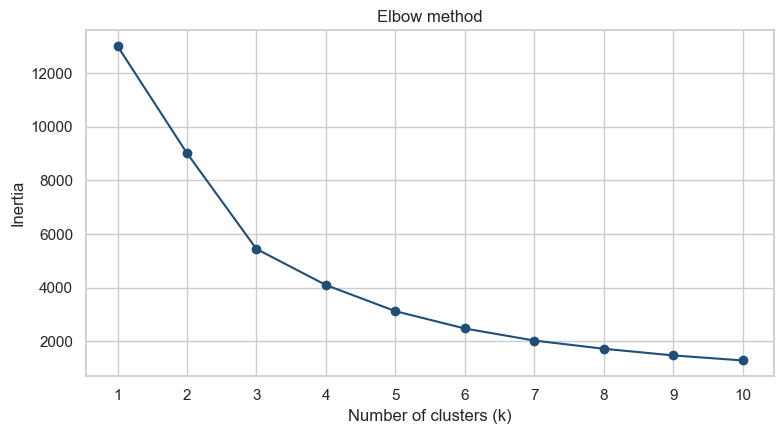

1     13014.0
2      9015.0
3      5441.0
4      4096.0
5      3120.0
6      2474.0
7      2024.0
8      1717.0
9      1469.0
10     1281.0
Name: inertia, dtype: float64

In [7]:
inertias = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(scaled)
    inertias.append(model.inertia_)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, 11), inertias, marker="o", color="#1f4e79")
ax.set_xticks(range(1, 11))
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia")
ax.set_title("Elbow method")
fig.tight_layout()
plt.show()

pd.Series(inertias, index=range(1, 11), name="inertia").round(0)


Inertia falls by about 4,000 when moving from 1 cluster to 2, and by about 3,600 from 2 to 3. The next step, from 3 to 4, only removes about 1,300, and every later step removes less. The bend is at 3 clusters. That is the k used below.


## 6. Cluster fit and profiles


In [8]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
rfm = rfm.copy()
rfm["Cluster"] = kmeans.fit_predict(scaled)

means = rfm.groupby("Cluster")["Monetary"].mean().sort_values(ascending=False)
segment_names = {
    means.index[0]: "Key accounts",
    means.index[1]: "Active core",
    means.index[2]: "Lapsed",
}
rfm["Segment"] = rfm["Cluster"].map(segment_names)

profile = rfm.groupby("Segment").agg(
    customers=("Recency", "size"),
    recency_days=("Recency", "mean"),
    frequency=("Frequency", "mean"),
    monetary=("Monetary", "mean"),
    revenue=("Monetary", "sum"),
)
profile["revenue_share_pct"] = profile["revenue"] / profile["revenue"].sum() * 100
profile = profile.reindex(["Key accounts", "Active core", "Lapsed"])
profile.round(2)


,customers,recency_days,frequency,monetary,revenue,revenue_share_pct
Segment,,,,,,
Key accounts,26,6.04,66.42,85826.08,2.23e+06,25.11
Active core,3230,41.45,4.67,1849.67,5.97e+06,67.23
Lapsed,1082,247.11,1.58,629.66,6.81e+05,7.67


**Key accounts.** 26 customers, last purchase about 6 days ago, about 66 invoices each, and an average spend of about 85,826 pounds. They are 0.6% of customers and 25.1% of revenue. These are the wholesale relationships.

**Active core.** 3,230 customers, last purchase about 41 days ago, about 4.7 invoices, and an average spend of about 1,850 pounds. They are most of the file and 67.2% of revenue.

**Lapsed.** 1,082 customers, last purchase about 247 days ago, about 1.6 invoices, and an average spend of about 630 pounds. They contribute 7.7% of revenue and have mostly stopped ordering.


## 7. Cluster charts


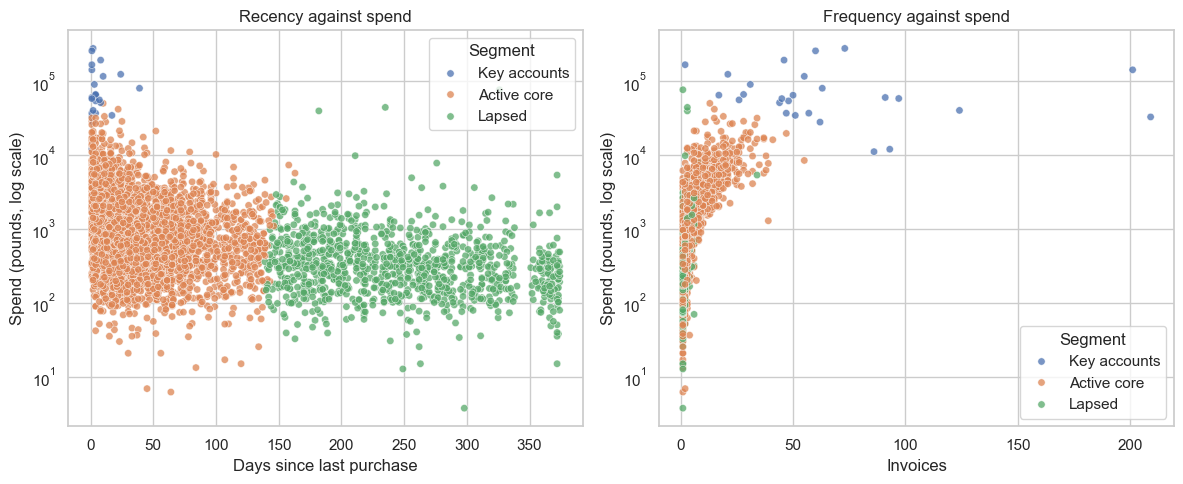

In [9]:
segment_order = ["Key accounts", "Active core", "Lapsed"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(
    data=rfm, x="Recency", y="Monetary", hue="Segment", hue_order=segment_order,
    ax=axes[0], s=28, alpha=0.75,
)
axes[0].set_yscale("log")
axes[0].set_title("Recency against spend")
axes[0].set_xlabel("Days since last purchase")
axes[0].set_ylabel("Spend (pounds, log scale)")

sns.scatterplot(
    data=rfm, x="Frequency", y="Monetary", hue="Segment", hue_order=segment_order,
    ax=axes[1], s=28, alpha=0.75,
)
axes[1].set_yscale("log")
axes[1].set_title("Frequency against spend")
axes[1].set_xlabel("Invoices")
axes[1].set_ylabel("Spend (pounds, log scale)")
fig.tight_layout()
plt.show()


The log scale keeps the wholesale accounts visible without flattening everyone else. Key accounts sit at the top: many invoices and a very recent order. The active core forms the dense band underneath them. Lapsed customers sit on the right of the recency chart, past 200 days, and on the left of the frequency chart, on one or two invoices.


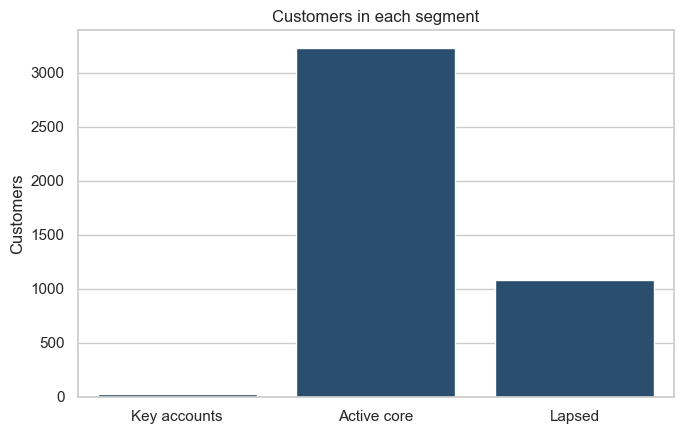

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.countplot(data=rfm, x="Segment", order=segment_order, ax=ax, color="#1f4e79")
ax.set_title("Customers in each segment")
ax.set_xlabel("")
ax.set_ylabel("Customers")
fig.tight_layout()
plt.show()


The headcount chart is the opposite of the revenue split. The active core is the crowd, the lapsed group is large enough to be a real list, and the key accounts are a handful of names. A campaign aimed at "all customers" would spend most of its messages on the core and still miss the fact that 26 accounts produce a quarter of the sales.


## 8. What to do with each segment

**Key accounts.** Give each of the 26 accounts a named owner. Offer case quantities and hold the products they reorder. Keep them off blanket discount emails. A site-wide 10% code trains a wholesale buyer to pay less for an order they were already going to place.

**Active core.** This is the business: 67% of revenue. Their typical gap between purchases is about 41 days, so a reorder reminder around that point fits the way they already buy. A small loyalty credit is enough. A deep discount would teach the largest group to wait for a sale.

**Lapsed.** Send one win-back offer with an end date. Most of these customers bought once or twice and have been gone for about eight months. If they do not return to that offer, stop paying to contact them. They are 7.7% of revenue, and further messages cost more than they return.
